# Missing Indicators with Scikit-learn

This notebook implements missing-value indicators with scikit-learn and compares them with Feature-engine's `AddMissingIndicator` behavior.

We will:
1. Load and split the Ames House Prices data.
2. Create indicators for selected variables using `MissingIndicator`.
3. Combine indicators with numeric and categorical imputation.
4. Use `SimpleImputer(add_indicator=True)` automatically.
5. Inspect indicators learned only from training data.

In [1]:
from pathlib import Path
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import MissingIndicator, SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

cwd = Path.cwd().resolve()
search_roots = [cwd, *cwd.parents]
candidates = [Path("houseprice.csv"), Path("feature-engineering/imputation/houseprice.csv")]
csv_path = next((root / c for root in search_roots for c in candidates if (root / c).exists()), None)
if csv_path is None:
    raise FileNotFoundError("houseprice.csv was not found through relative project paths.")

csv_relative_path = Path(os.path.relpath(csv_path.resolve(), cwd))
data = pd.read_csv(csv_path.resolve())
print("Dataset:", csv_relative_path)
print("Shape:", data.shape)
data.head()

Dataset: houseprice.csv
Shape: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## 1. Inspect missing data and split before preprocessing

In [2]:
selected = ["Alley", "MasVnrType", "LotFrontage", "MasVnrArea"]

X = data.drop(columns=["Id", "SalePrice"])
y = data["SalePrice"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)

print("Training shape:", X_train.shape)
print("Test shape:", X_test.shape)
X_train[selected].isna().mean().sort_values(ascending=False)

Training shape: (1022, 79)
Test shape: (438, 79)


Alley          0.939335
MasVnrType     0.600783
LotFrontage    0.184932
MasVnrArea     0.004892
dtype: float64

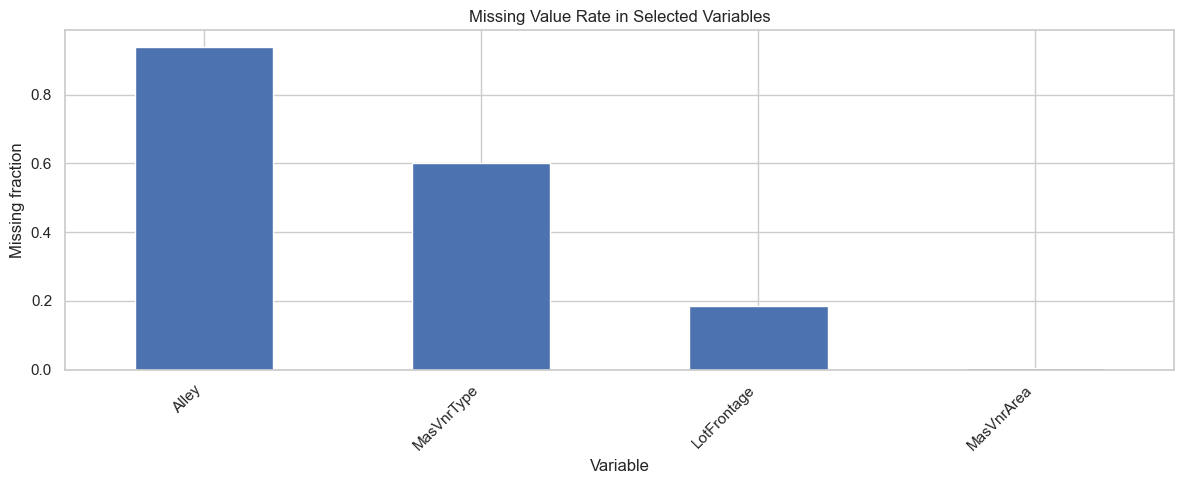

In [3]:
missing_rate = X_train[selected].isna().mean().sort_values(ascending=False)
missing_rate.plot(kind="bar", color="#4C72B0")
plt.title("Missing Value Rate in Selected Variables")
plt.ylabel("Missing fraction")
plt.xlabel("Variable")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 2. Create indicators for selected variables

`MissingIndicator` returns a NumPy array containing binary indicator columns. It does not modify the original DataFrame, so we convert the result to named DataFrame columns below.

In [4]:
indicator = MissingIndicator(features="missing-only")
indicator.fit(X_train[selected])
train_indicators = indicator.transform(X_train[selected])
test_indicators = indicator.transform(X_test[selected])

indicator_sources = np.asarray(selected)[indicator.features_]
indicator_names = [f"{column}_missing" for column in indicator_sources]
train_indicator_df = pd.DataFrame(train_indicators, columns=indicator_names, index=X_train.index)
test_indicator_df = pd.DataFrame(test_indicators, columns=indicator_names, index=X_test.index)

print("Indicator source columns:", indicator_sources.tolist())
train_indicator_df.head()

Indicator source columns: ['Alley', 'MasVnrType', 'LotFrontage', 'MasVnrArea']


,Alley_missing,MasVnrType_missing,LotFrontage_missing,MasVnrArea_missing
64,True,False,True,False
682,True,True,True,False
960,True,True,False,False
1384,True,True,False,False
1100,True,True,False,False


## 3. Compare original missing values with generated indicators

In [5]:
comparison = pd.concat([
    X_train[selected].isna().astype(int).add_suffix("_original_missing"),
    train_indicator_df
], axis=1)
comparison.head(8)

,Alley_original_missing,MasVnrType_original_missing,LotFrontage_original_missing,MasVnrArea_original_missing,Alley_missing,MasVnrType_missing,LotFrontage_missing,MasVnrArea_missing
64,1,0,1,0,True,False,True,False
682,1,1,1,0,True,True,True,False
960,1,1,0,0,True,True,False,False
1384,1,1,0,0,True,True,False,False
1100,1,1,0,0,True,True,False,False
416,1,0,0,0,True,False,False,False
1034,1,1,0,0,True,True,False,False
853,1,0,1,0,True,False,True,False


## 4. Impute original variables and join indicators

- Numeric variables are imputed with their training median.
- Categorical variables are imputed with their training most-frequent category.
- Indicator columns are joined afterward.

In [6]:
numeric_selected = ["LotFrontage", "MasVnrArea"]
categorical_selected = ["Alley", "MasVnrType"]

train_imputed = X_train[selected].copy()
test_imputed = X_test[selected].copy()

numeric_imputer = SimpleImputer(strategy="median")
train_imputed[numeric_selected] = numeric_imputer.fit_transform(X_train[numeric_selected])
test_imputed[numeric_selected] = numeric_imputer.transform(X_test[numeric_selected])

categorical_imputer = SimpleImputer(strategy="most_frequent")
train_imputed[categorical_selected] = categorical_imputer.fit_transform(X_train[categorical_selected])
test_imputed[categorical_selected] = categorical_imputer.transform(X_test[categorical_selected])

train_completed = pd.concat([train_imputed, train_indicator_df], axis=1)
test_completed = pd.concat([test_imputed, test_indicator_df], axis=1)

print("Remaining missing values:", int(train_completed.isna().sum().sum()))
train_completed.head()

Remaining missing values: 0


,Alley,MasVnrType,LotFrontage,MasVnrArea,Alley_missing,MasVnrType_missing,LotFrontage_missing,MasVnrArea_missing
64,Pave,BrkFace,69.0,573.0,True,False,True,False
682,Pave,BrkFace,69.0,0.0,True,True,True,False
960,Pave,BrkFace,50.0,0.0,True,True,False,False
1384,Pave,BrkFace,60.0,0.0,True,True,False,False
1100,Pave,BrkFace,60.0,0.0,True,True,False,False


## 5. Automatically select all variables with missing training values

In [7]:
automatic_indicator = MissingIndicator(features="missing-only")
automatic_indicator.fit(X_train)
automatic_sources = X_train.columns[automatic_indicator.features_].tolist()
automatic_matrix = automatic_indicator.transform(X_train)

print("Variables with missing values:", automatic_sources)
print("Number of indicator variables:", len(automatic_sources))
print("Indicator matrix shape:", automatic_matrix.shape)

Variables with missing values: ['LotFrontage', 'Alley', 'MasVnrType', 'MasVnrArea', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Electrical', 'FireplaceQu', 'GarageType', 'GarageYrBlt', 'GarageFinish', 'GarageQual', 'GarageCond', 'PoolQC', 'Fence', 'MiscFeature']
Number of indicator variables: 19
Indicator matrix shape: (1022, 19)


## 6. Combined numeric and categorical pipeline

`SimpleImputer(add_indicator=True)` both creates missing indicators and imputes the original values. We separate numeric and categorical columns with `ColumnTransformer`.

In [8]:
numeric_columns = X_train.select_dtypes(include=[np.number]).columns.tolist()
categorical_columns = X_train.select_dtypes(exclude=[np.number]).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True))
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent", add_indicator=True))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_columns),
    ("categorical", categorical_pipeline, categorical_columns)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Original training shape:", X_train.shape)
print("Processed training shape:", X_train_processed.shape)
print("Remaining missing values:", pd.DataFrame(X_train_processed).isna().sum().sum())

Original training shape: (1022, 79)
Processed training shape: (1022, 98)
Remaining missing values: 0


In [9]:
for transformer_name, transformer, columns in preprocessor.transformers_:
    if transformer_name == "remainder":
        continue
    imputer = transformer.named_steps["imputer"]
    indicator_transformer = getattr(imputer, "indicator_", None)
    if indicator_transformer is not None:
        sources = np.asarray(columns)[indicator_transformer.features_].tolist()
        print(transformer_name, "indicator sources:", sources)

try:
    names = preprocessor.get_feature_names_out()
    print("Example output names:", names[:15].tolist())
except Exception as exc:
    print("Feature names unavailable:", exc)

numeric indicator sources: ['LotFrontage', 'MasVnrArea', 'GarageYrBlt']
categorical indicator sources: ['Alley', 'MasVnrType', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Electrical', 'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond', 'PoolQC', 'Fence', 'MiscFeature']
Example output names: ['numeric__MSSubClass', 'numeric__LotFrontage', 'numeric__LotArea', 'numeric__OverallQual', 'numeric__OverallCond', 'numeric__YearBuilt', 'numeric__YearRemodAdd', 'numeric__MasVnrArea', 'numeric__BsmtFinSF1', 'numeric__BsmtFinSF2', 'numeric__BsmtUnfSF', 'numeric__TotalBsmtSF', 'numeric__1stFlrSF', 'numeric__2ndFlrSF', 'numeric__LowQualFinSF']


## 8. Summary

- `MissingIndicator(features="missing-only")` creates binary missingness features for variables selected during training.
- `SimpleImputer(..., add_indicator=True)` adds indicators while imputing values in one step.
- In a scikit-learn pipeline, indicator positions and names are exposed by the transformed output, rather than as named pandas columns by default.
- To add a named `_na` column directly to a DataFrame, Feature-engine's `AddMissingIndicator` is more convenient.
- Always fit preprocessing and indicators on training data to prevent data leakage.